# Plot SVM Results From Saved Data

Run the cells below to load saved experiment data and recreate the figures without rerunning the SVM experiments.

In [79]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np

from SVM_utils import plot_figures, plot_for_paper_2

In [80]:
# Select the saved data file. Use svm_results_full.pkl for experiment_SVM.ipynb.
DATA_FILE = Path("svm_results_full.pkl")

if not DATA_FILE.exists():
    DATA_FILE = Path("SVM") / DATA_FILE

with DATA_FILE.open("rb") as result_file:
    results = pickle.load(result_file)

histories_by_label = results["histories"]
labels = results["labels"]
histories = [histories_by_label[label] for label in histories_by_label]

# Methods without a line-search step use their ordinary per-iteration values.
for history in histories:
    history.setdefault("func_at_lssolve", history["func"])
    history.setdefault("grad_norm_at_lssolve", history["grad_norm"])

print(f"Loaded {len(histories)} histories from {DATA_FILE}")

Loaded 9 histories from svm_results_full.pkl


In [81]:
# Change these values to adjust the appearance of all figures.
colors = [
    "#E8601C",
    "pink",
    "gold",
    "black",
    "#9B8AC4",
    "#88A5DD",
    "#8DCBE4",
    "#C2E3D2",
    "#DDECBF",
]
linewidths = [2.0] * len(histories)
linestyles = ["-"] * len(histories)
f_star = min(np.min(history["func"]) for history in histories)

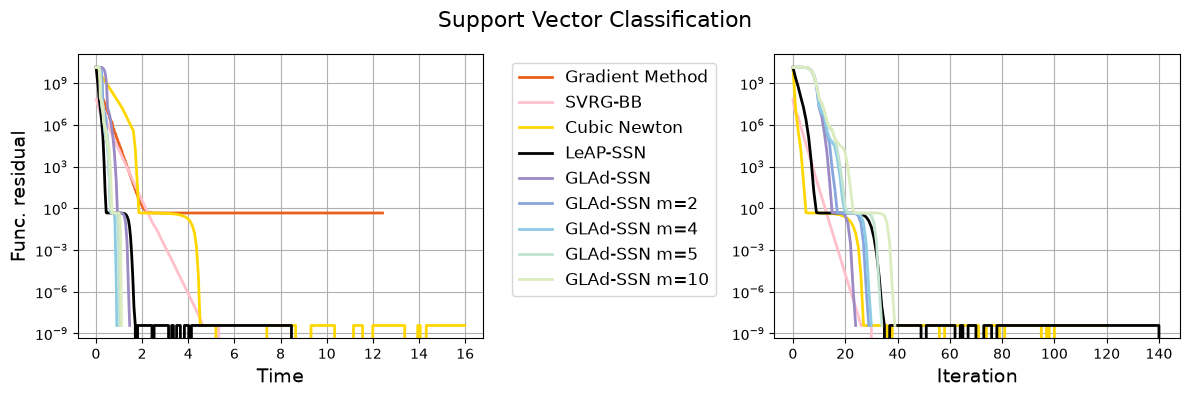

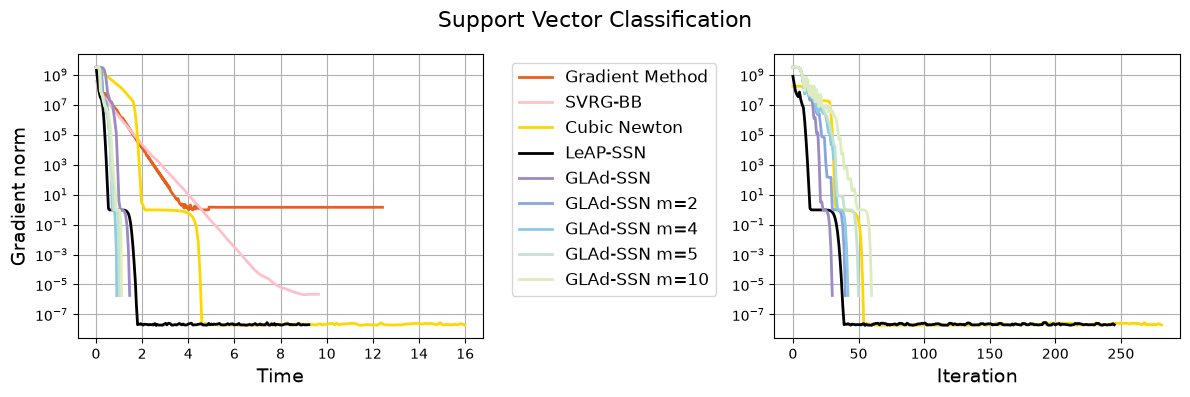

In [82]:
is_full_experiment = len(histories) > 3
which_measure_2 = "func" if is_full_experiment else "func_at_lssolve"

plot_figures(
    histories,
    labels,
    colors=colors,
    linewidths=linewidths,
    linestyles=linestyles,
    n=100,
    m=None,
    mu_str="0.5",
    f_star=f_star,
    threshold=1e-10,
    suptitle="Support Vector Classification",
    which_measure_2=which_measure_2,
    max_iter=1000,
)

# The second panel uses grad_norm_at_lssolve; empty only SVRG-BB's series there.
gradient_plot_histories = [history.copy() for history in histories]
if "SVRG-BB" in labels:
    gradient_plot_histories[labels.index("SVRG-BB")]["grad_norm_at_lssolve"] = np.empty(0)

plot_figures(
    gradient_plot_histories,
    labels,
    colors=colors,
    linewidths=linewidths,
    linestyles=linestyles,
    n=100,
    m=None,
    mu_str="0.5",
    f_star=0,
    threshold=1e-10,
    suptitle="Support Vector Classification",
    max_iter=1000,
    which_measure_1="grad_norm",
    which_measure_2="grad_norm_at_lssolve",
    ylabel="Gradient norm",
)

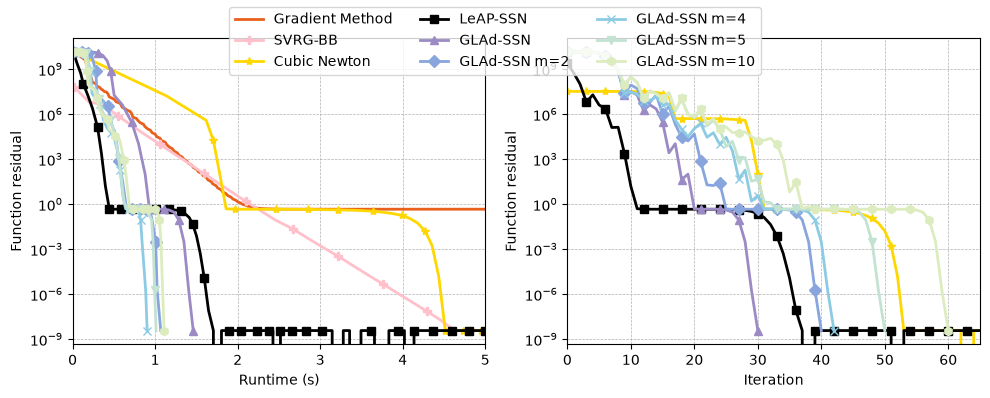

In [83]:
# Reproduce the paper plot from experiment_SVM.ipynb.
m_cycle = ["None", "P", "*", "s", "^", "D", "x", "v", "h"]
markevery_numbers = [3] * 10

paper_plot_histories = [history.copy() for history in histories]
if "SVRG-BB" in labels:
    paper_plot_histories[labels.index("SVRG-BB")]["func_at_lssolve"] = np.empty(0)

plot_for_paper_2(
    paper_plot_histories,
    labels,
    colors=colors,
    linewidths=linewidths,
    linestyles=linestyles,
    n=100,
    m=None,
    mu_str="0.5",
    f_star=f_star,
    threshold=1e-10,
    suptitle="Support Vector Classification",
    max_iter=65,
    clip_time=5,
    m_cycle=m_cycle,
    markevery_numbers=markevery_numbers,
)

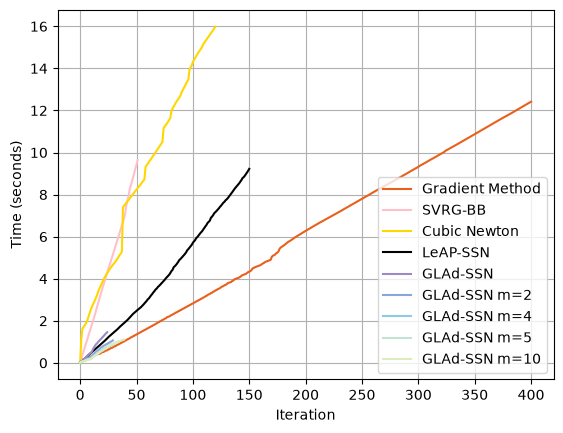

In [84]:
for label, history, color in zip(labels, histories, colors):
    times = history["time"]
    iters = range(len(times))
    plt.plot(iters, times, label=label, color=color)

plt.xlabel("Iteration")
plt.ylabel("Time (seconds)")
plt.legend()
plt.grid(True)
plt.show()